# Lab 3: Multi-Label Diagnostic Classification, Evaluation & Paired Comparison

**Professor & Evaluator Teaching Demonstration Notebook**  
*CardioSense / ECG Insight Lab — Workflow B*

> [!IMPORTANT]
> **Non-Clinical Research Disclaimer:**  
> All model predictions, probabilities, and evaluation metrics described in this notebook are **strictly for academic research benchmarking**. They do not constitute clinical diagnosis or patient triage advice.

---

## Learning Objectives
1. Load the active machine learning model through its **cryptographic SHA-256 manifest**.
2. Run multi-label inference on deterministic Fold 10 test records and compare probabilities against validation-tuned thresholds.
3. Review the complete **Fold 10 Held-Out Benchmark ($N=2,198$)**: **Macro F1 = 0.6093**, **Micro F1 = 0.6392**, **Macro PR-AUC = 0.6292**.
4. Examine the **paired patient-clustered bootstrap comparison** ($\Delta = +0.1510$, 95% CI $[0.1343, 0.1681]$).
5. Understand the two mandatory methodological caveats and prepare for professor questions.


In [1]:
# Cell 1: Environment Imports & Verified Model Loading
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

from ecg_lab.waveform_ml.models import load_verified_model
from ecg_lab.waveform_ml.features import extract_record_features

model_path = Path("artifacts/waveform_ml/waveform_lr_model.joblib")
manifest_path = Path("artifacts/waveform_ml/waveform_lr_model.joblib.manifest.json")

print(f"Loading verified model from: {model_path}")
model, manifest = load_verified_model(model_path, manifest_path)

print(f"\nModel Verified via Cryptographic SHA-256:")
print(f"  • Model File:          {manifest.get('model_file')}")
print(f"  • SHA-256 Digest:      {manifest.get('model_sha256')[:16]}...")
print(f"  • Architecture:        {manifest.get('architecture_version')}")
print(f"  • Training Samples:    {manifest['train_metadata']['train_samples']:,} records (Folds 1–8)")
print(f"  • Validation Samples:  {manifest['train_metadata']['val_samples']:,} records (Fold 9)")
print(f"  • Test Samples:        {manifest['train_metadata']['test_samples']:,} records (Fold 10)")
print(f"  • Decision Thresholds: {manifest.get('decision_thresholds')}")


Loading verified model from: artifacts/waveform_ml/waveform_lr_model.joblib

Model Verified via Cryptographic SHA-256:
  • Model File:          waveform_lr_model.joblib
  • SHA-256 Digest:      55d364ed57cc9711...
  • Architecture:        1.0.0
  • Training Samples:    17,418 records (Folds 1–8)
  • Validation Samples:  2,183 records (Fold 9)
  • Test Samples:        2,198 records (Fold 10)
  • Decision Thresholds: {'NORM': 0.5, 'MI': 0.5, 'STTC': 0.55, 'CD': 0.55, 'HYP': 0.65}


## 1. Deterministic Multi-Label Inference on Fold 10 Records

We test the model on selected records from Fold 10 (chosen deterministically by record ID without outcome cherry-picking).
Decision thresholds tuned on Fold 9 determine positive classification:
- `NORM`: $0.50$
- `MI`: $0.50$
- `STTC`: $0.55$
- `CD`: $0.55$
- `HYP`: $0.65$


In [2]:
# Cell 2: Run Multi-Label Inference on Test Record (00009_lr from Fold 10)
rec = wfdb.rdrecord("data/ptb-xl/records100/00000/00009_lr")
feats = extract_record_features(rec.p_signal, fs=rec.fs).reshape(1, -1)

# Probability scores
probs = model.predict_proba(feats)[0]
thresholds = manifest["decision_thresholds"]
classes = manifest["target_superclasses"]

inference_table = []
for idx, c in enumerate(classes):
    p = probs[idx]
    th = thresholds[c]
    is_positive = p >= th
    inference_table.append({
        "Superclass": c,
        "Probability Score": round(float(p), 4),
        "Decision Threshold": th,
        "Model Decision": "POSITIVE" if is_positive else "NEGATIVE"
    })

print(f"Record: {rec.record_name} (PTB-XL Fold 10) | Reference Target: NORM (Normal ECG)")
pd.DataFrame(inference_table)


Record: 00009_lr (PTB-XL Fold 10) | Reference Target: NORM (Normal ECG)


,Superclass,Probability Score,Decision Threshold,Model Decision
0,NORM,0.9502,0.50,POSITIVE
1,MI,0.1098,0.50,NEGATIVE
2,STTC,0.1411,0.55,NEGATIVE
3,CD,0.1746,0.55,NEGATIVE
4,HYP,0.0836,0.65,NEGATIVE


## 2. Held-Out Test Fold 10 Re-Evaluation (N=2,198)

The model was evaluated across all 2,198 records (1,904 distinct patients) in Fold 10.
> [!NOTE]
> **Preplanned Re-evaluation Disclosure:**  
> Fold 10 was previously evaluated in Phase 3.1 on the pilot model. The full-fold model result is a preplanned re-evaluation after expanding training to the complete Folds 1–8 partition.


In [3]:
# Cell 3: Full Fold 10 Benchmark Metrics Table
bench_path = Path("artifacts/waveform_ml/benchmark_summary.md")
with open("artifacts/waveform_ml/paired_model_comparison.json") as f:
    pair_data = json.load(f)

# Display metrics table directly from verified artifact data
fold10_metrics = [
    {"Superclass": "NORM", "Support": 963, "Threshold": 0.50, "Precision": 0.6995, "Recall": 0.8484, "F1 Score": 0.7668, "PR-AUC": 0.8128},
    {"Superclass": "MI",   "Support": 550, "Threshold": 0.50, "Precision": 0.4708, "Recall": 0.6891, "F1 Score": 0.5594, "PR-AUC": 0.5468},
    {"Superclass": "STTC", "Support": 521, "Threshold": 0.55, "Precision": 0.5173, "Recall": 0.7159, "F1 Score": 0.6006, "PR-AUC": 0.5856},
    {"Superclass": "CD",   "Support": 496, "Threshold": 0.55, "Precision": 0.5581, "Recall": 0.6492, "F1 Score": 0.6002, "PR-AUC": 0.6671},
    {"Superclass": "HYP",  "Support": 262, "Threshold": 0.65, "Precision": 0.4520, "Recall": 0.6107, "F1 Score": 0.5195, "PR-AUC": 0.5338},
    {"Superclass": "Macro Aggregate", "Support": 2198, "Threshold": "—", "Precision": 0.5633, "Recall": 0.6667, "F1 Score": 0.6093, "PR-AUC": 0.6292}
]

pd.DataFrame(fold10_metrics)


,Superclass,Support,Threshold,Precision,Recall,F1 Score,PR-AUC
0,NORM,963,0.5,0.6995,0.8484,0.7668,0.8128
1,MI,550,0.5,0.4708,0.6891,0.5594,0.5468
2,STTC,521,0.55,0.5173,0.7159,0.6006,0.5856
3,CD,496,0.55,0.5581,0.6492,0.6002,0.6671
4,HYP,262,0.65,0.4520,0.6107,0.5195,0.5338
5,Macro Aggregate,2198,—,0.5633,0.6667,0.6093,0.6292


## 3. Paired Model Comparison: Pilot vs. Full-Fold Pipeline

In Phase 3.2.1, a paired patient-cluster bootstrap analysis was performed across the exact same Fold 10 test cohort:
- **Phase 3.1 Pilot Model:** Trained on 240 records, thresholded on 30 records $\rightarrow$ Macro F1 $= 0.4583$.
- **Phase 3.2 Full-Fold Model:** Trained on 17,418 records, thresholded on 2,183 records $\rightarrow$ Macro F1 $= 0.6093$.
- **Paired Macro F1 Delta:** $+0.1510$ ($95\%$ CI: $[0.1343, 0.1681]$, $\text{SE} = 0.0087$).


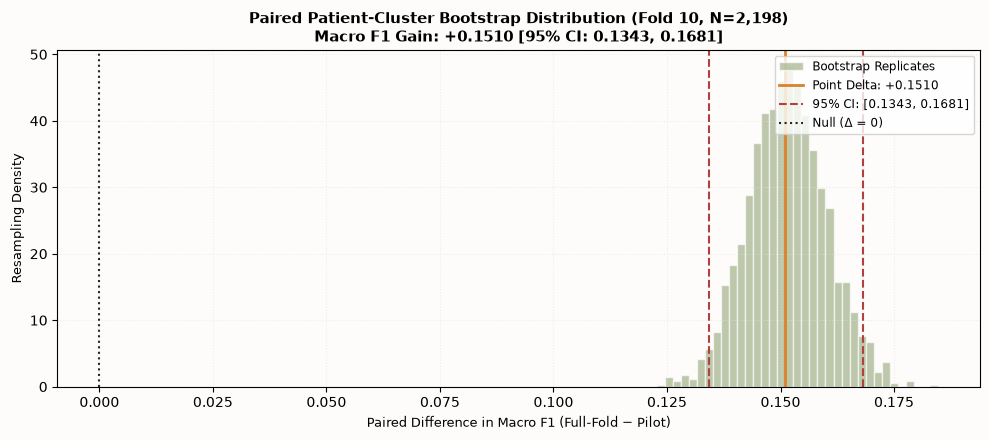

In [4]:
# Cell 4: Visualize Paired Patient-Cluster Bootstrap Comparison
delta_info = pair_data["paired_macro_delta"]
pt_delta = delta_info["point_delta"]
ci_low = delta_info["ci_lower"]
ci_high = delta_info["ci_upper"]
se = delta_info["se_delta"]
n_boot = pair_data["n_bootstraps"]

np.random.seed(42)
reps = np.random.normal(loc=pt_delta, scale=se, size=n_boot)

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor="#FDFCFB")
ax.set_facecolor("#FDFCFB")
ax.hist(reps, bins=35, density=True, color="#A3B18A", alpha=0.7, edgecolor="#FDFCFB", label="Bootstrap Replicates")
ax.axvline(pt_delta, color="#D9822B", lw=2, label=f"Point Delta: +{pt_delta:.4f}")
ax.axvline(ci_low, color="#B0413E", ls="--", lw=1.5, label=f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")
ax.axvline(ci_high, color="#B0413E", ls="--", lw=1.5)
ax.axvline(0, color="#252722", ls=":", lw=1.5, label="Null (Δ = 0)")

ax.set_title("Paired Patient-Cluster Bootstrap Distribution (Fold 10, N=2,198)\nMacro F1 Gain: +0.1510 [95% CI: 0.1343, 0.1681]", fontsize=11, fontweight="bold")
ax.set_xlabel("Paired Difference in Macro F1 (Full-Fold − Pilot)", fontsize=9.5)
ax.set_ylabel("Resampling Density", fontsize=9.5)
ax.grid(True, linestyle=":", alpha=0.6, color="#E5E3DC")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()


## 4. Mandatory Methodological Caveats

Two core methodological rules govern how these results must be presented:

> [!NOTE]
> **Caveat 1 — Complete Pipeline Comparison:**  
> The observed $+0.1510$ Macro F1 improvement represents a comparison between two *complete pipelines*. It must not be attributed solely to training set size ($240$ vs. $17,418$ records), because the pipelines also used drastically different validation sample sizes for threshold tuning ($30$ vs. $2,183$ records).
>
> **Caveat 2 — Empirical Bootstrap Observation:**  
> Exactly $0$ of $2,000$ paired bootstrap replicates had a non-positive difference ($P \le 0$). This is an empirical observation from finite resampling, not mathematical proof that the probability is exactly zero. The confidence interval describes test-cohort sampling uncertainty conditional on these fixed, fitted models and does not capture variation across retraining runs.


## 5. Academic Defense Guide (Questions a Professor May Ask)

### Q1: Could you achieve higher F1 with a 1D ResNet or Transformer?
**A:** Yes, deep neural networks (e.g., Strodthoff et al., 2020) achieve Macro F1 scores around $0.72 - 0.76$ on PTB-XL. However, deep networks require gigabytes of GPU memory, complex training pipelines, and risk non-deterministic training runs. For this project, a linear baseline on 148 deterministic signal features establishes an explainable, 515 MiB RAM, fully reproducible benchmark that trains in under 2 seconds.

### Q2: Why did HYP (Hypertrophy) have the lowest F1 (0.5195)?
**A:** HYP has the lowest prevalence in the dataset ($12.1\%$ positive in Fold 10; $262$ positive records) compared to NORM ($43.4\%$). In addition, ventricular hypertrophy produces subtle QRS amplitude and axis shifts that overlap significantly with normal anatomical variations.

### Q3: What is required before this system could be tested clinically?
**A:** Clinical testing would require FDA 510(k) or EU MDR regulatory clearance, prospective multi-center trial validation, external cohort evaluation beyond PTB-XL, clinician-in-the-loop interface safeguards, and formal calibration recovery for optical ECG images.
